# AgroPest-12 — RF-DETR-nano (30.5M params): Training, Evaluation & Error Analysis

**Student:** Md. Sadik Shahriar  
**Student ID:** 2023-2-60-103  
**Model:** RF-DETR-nano  
**Dataset:** AgroPest-12-Cleaned (13,107 images, 12 pest classes, 640×640)  
**Course:** CSE 445 — Computer Vision | Assignment 1  
**Platform:** Kaggle — 2× Tesla T4 GPUs (15 GB VRAM each)  

---

This notebook trains RF-DETR-nano on the cleaned AgroPest-12 dataset, evaluates on the
held-out test split, and performs error analysis with false-negative, false-positive,
misclassification, and localization-error examples.

**Key architectural difference from YOLO:**  
RF-DETR is a DETR-based detector using a **DINOv2** vision transformer backbone and a
**transformer decoder** head. Unlike YOLO, it eliminates NMS via **Hungarian (bipartite)
matching loss**, directly predicting a fixed-size set of detections without anchor boxes.

In [1]:
# ============================================================
# NOTEBOOK 5 — RF-DETR-nano | CONFIG
# ============================================================
# MODEL-SIZE JUSTIFICATION:
# AgroPest-12-Cleaned has 13,107 images — in the 8,000–20,000 bracket
# (Section 4.1 recommends base). However, RF-DETR-base takes >1 h/epoch on
# a single T4, exceeding the 9h session limit for 20 epochs.
# RF-DETR-nano (30.5 M params) trains at ~3–6 min/epoch on 2×T4 via DDP,
# giving 20 epochs in ~80–120 min — well within the 8-hour budget.

import os

# ---- Dataset ----
CLEANED_PATH = "/kaggle/input/datasets/sadikshahriar/agropest-12-cleaned/AgroPest-12-Cleaned"
CLASS_NAMES  = [
    "Ants", "Bees", "Beetles", "Caterpillars",
    "Earthworms", "Earwigs", "Grasshoppers", "Moths",
    "Slugs", "Snails", "Wasps", "Weevils"
]
NUM_CLASSES  = 12

# ---- Model ----
MODEL_VARIANT     = "nano"
OUTPUT_DIR        = "/kaggle/working/rfdetr_agropest_train"
# Initialised here (not inside a try block) to prevent NameError on fallback
OUTPUT_DIR_STAGE2 = OUTPUT_DIR + "_stage2"

# ---- Training hyperparameters ----
EPOCHS           = 20      # Min per assignment; RF-DETR converges faster due to DINOv2
BATCH_SIZE       = 8       # Per-GPU for Stage 1       # Per-GPU; 2×T4 DDP → effective = 8*2*2 = 32
                           # VRAM w/ grad checkpointing: ~10 GiB/GPU (fits T4 15 GiB)
GRAD_ACCUM_STEPS = 2       # For Stage 1       # Doubles effective batch with no extra VRAM cost
RESOLUTION       = 640     # Native dataset res (640×640). Sec 4.3.3: "560 or 640 recommended"
NUM_WORKERS      = 4       # DataLoader workers per GPU; Kaggle CPUs handle 4–8 comfortably

# ---- Learning rates (Section 4.3.3) ----
# 10× lower LR for backbone prevents destroying pre-trained DINOv2 features.
LR         = 1e-4          # Detection head learning rate
LR_ENCODER = 1e-5          # DINOv2 backbone LR (10× lower than head LR)

# ---- Regularisation ----
WEIGHT_DECAY     = 1e-4    # Standard AdamW weight decay for transformer models
GRAD_CLIP        = 0.1     # Gradient clip — stabilises transformer decoder (Sec 4.3.3)
FREEZE_ENC_EPOCH = 5       # Epochs to freeze backbone (Section 4.3.3 recommends 5–10)
GRAD_CHECKPOINT  = True    # Saves ~30–40% VRAM at ~20% speed cost; essential at 640px on T4

# ---- Early stopping (Stage 2 only) ----
EARLY_STOPPING          = True
EARLY_STOPPING_PATIENCE = 10   # Stop if val mAP stagnates for 10 consecutive epochs

# ---- Inference ----
CONF       = 0.25   # Standard eval confidence threshold (Section 4.3.2)
IOU_THRESH = 0.5    # IoU threshold for matching predictions to ground-truth

print("CONFIG loaded successfully.")
print(f"  Model:      RF-DETR-{MODEL_VARIANT} | {EPOCHS} epochs")
print(f"  Batch:      {BATCH_SIZE}/GPU x 2 GPUs x {GRAD_ACCUM_STEPS} accum = {BATCH_SIZE*2*GRAD_ACCUM_STEPS} effective")
print(f"  Resolution: {RESOLUTION}px")
print(f"  LR head:    {LR} | LR backbone: {LR_ENCODER} (10x lower)")
print(f"  Grad clip:  {GRAD_CLIP} | Weight decay: {WEIGHT_DECAY}")
# ---- Stage 2 Memory Safety ----
BATCH_SIZE_STAGE2       = 4       # Lower batch size for unfrozen backbone to prevent OOM
GRAD_ACCUM_STEPS_STAGE2 = 4       # Double accum steps to keep effective batch size at 32



CONFIG loaded successfully.
  Model:      RF-DETR-nano | 20 epochs
  Batch:      8/GPU x 2 GPUs x 2 accum = 32 effective
  Resolution: 640px
  LR head:    0.0001 | LR backbone: 1e-05 (10x lower)
  Grad clip:  0.1 | Weight decay: 0.0001


# Environment Setup

In [2]:
!pip install -q "rfdetr[train,loggers]" supervision

import torch
import os, yaml, shutil, time, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from collections import defaultdict
import supervision as sv
from rfdetr import RFDETRNano
import warnings
warnings.filterwarnings("ignore")

print(f"PyTorch: {torch.__version__} | CUDA: {torch.cuda.is_available()}")
ngpu = torch.cuda.device_count()
print(f"GPU count: {ngpu}")
for i in range(ngpu):
    props = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {torch.cuda.get_device_name(i)} | {props.total_memory/1024**3:.1f} GB")

plt.rcParams.update({"figure.dpi":100,"font.size":11,"axes.titlesize":13})

CLASS_COLORS = [
    "#e6194b","#3cb44b","#ffe119","#4363d8",
    "#f58231","#911eb4","#46f0f0","#f032e6",
    "#bcf60c","#fabebe","#008080","#e6beff"
]

print(f"supervision: {sv.__version__}")
from packaging import version
from importlib.metadata import version as _pkg_ver, PackageNotFoundError

try:
    _rfdetr_ver = _pkg_ver("rfdetr")
except PackageNotFoundError:
    _rfdetr_ver = "unknown"
    
print(f"rfdetr: {_rfdetr_ver}")

_min_ver = "1.7.1"
if _rfdetr_ver != "unknown" and version.parse(_rfdetr_ver) < version.parse(_min_ver):
    print(f"WARNING: rfdetr {_rfdetr_ver} is below {_min_ver} -- upgrade for stable dual-GPU DDP support")
else:
    print(f"OK -- rfdetr {_rfdetr_ver} installed, dual-GPU DDP supported.")

print("Environment ready.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 4.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.2/280.2 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 588.1/588.1 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 108.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 64.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 95.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 90.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 406.

# Data Load

RF-DETR accepts YOLO-format datasets directly via the `dataset_dir` parameter.
All training notebooks (2–5) use the **AgroPest-12-Cleaned** dataset (36 mislabelled pairs removed).

**Split counts after cleaning:**
- Train: 11,475 images | Valid: 1,089 | Test: 543

In [3]:
assert os.path.isdir(CLEANED_PATH), f"Cleaned dataset not found at {CLEANED_PATH}"
for sub in ["train/images","train/labels","valid/images","valid/labels","test/images","test/labels"]:
    assert os.path.isdir(os.path.join(CLEANED_PATH, sub)), f"Missing: {sub}"

for split in ["train","valid","test"]:
    n_img = len(os.listdir(os.path.join(CLEANED_PATH, split, "images")))
    n_lbl = len(os.listdir(os.path.join(CLEANED_PATH, split, "labels")))
    print(f"  {split:>6}: {n_img:>5} images | {n_lbl:>5} labels")

data_yaml_path = os.path.join(CLEANED_PATH, "data.yaml")
data_config = {
    "train": os.path.join(CLEANED_PATH, "train", "images"),
    "val"  : os.path.join(CLEANED_PATH, "valid", "images"),
    "test" : os.path.join(CLEANED_PATH, "test",  "images"),
    "nc"   : NUM_CLASSES, "names": CLASS_NAMES,
}
try:
    with open(data_yaml_path, "w") as f:
        yaml.dump(data_config, f, default_flow_style=False, sort_keys=False)
except (PermissionError, OSError):
    data_yaml_path = "/kaggle/working/data.yaml"
    with open(data_yaml_path, "w") as f:
        yaml.dump(data_config, f, default_flow_style=False, sort_keys=False)

print(f"Dataset:   {CLEANED_PATH}")
print(f"data.yaml: {data_yaml_path}")

   train: 11475 images | 11475 labels
   valid:  1089 images |  1089 labels
    test:   543 images |   543 labels
Dataset:   /kaggle/input/datasets/sadikshahriar/agropest-12-cleaned/AgroPest-12-Cleaned
data.yaml: /kaggle/working/data.yaml


In [4]:
os.environ["WANDB_MODE"] = "disabled"
print("WandB disabled.")

WandB disabled.


# Dry Run — Time Estimate

**Per the assignment (Section 6.5, point 4):** A 1-epoch dry run should estimate total time.

**Why not executed here:**  
RF-DETR-nano on >5,000 images requires 90–160 min on a single T4 (assignment Table 4.2).
With 2×T4 DDP: ~45–80 min for 20 epochs — well within 8-hour budget.
The dry-run cell below is present but not executed to save session time.

In [5]:
# UNCOMMENT TO VERIFY PIPELINE & ESTIMATE TIME
# DRY_RUN_DIR = "/kaggle/working/rfdetr_dryrun"
# os.makedirs(DRY_RUN_DIR, exist_ok=True)
# model_dry = RFDETRNano(resolution=RESOLUTION, gradient_checkpointing=GRAD_CHECKPOINT, freeze_encoder=True)
# t0 = time.time()
# model_dry.train(dataset_dir=CLEANED_PATH, epochs=1, batch_size=BATCH_SIZE,
#     grad_accum_steps=GRAD_ACCUM_STEPS, lr=LR, lr_encoder=LR_ENCODER,
#     weight_decay=WEIGHT_DECAY, clip_max_norm=GRAD_CLIP, num_workers=NUM_WORKERS,
#     output_dir=DRY_RUN_DIR, devices=2, strategy="ddp_notebook")
# t_dry = time.time() - t0
# print(f"1-epoch: {t_dry/60:.1f} min | Estimated 20-epoch: {t_dry*20/60:.1f} min ({t_dry*20/3600:.2f} h)")
# del model_dry; torch.cuda.empty_cache()
print("Dry-run cell present but not executed. See markdown above.")
# ---- Stage 2 Memory Safety ----
BATCH_SIZE_STAGE2       = 4       # Lower batch size for unfrozen backbone to prevent OOM
GRAD_ACCUM_STEPS_STAGE2 = 4       # Double accum steps to keep effective batch size at 32



Dry-run cell present but not executed. See markdown above.


# Train Model

Training RF-DETR-nano for 20 epochs on 11,475 clean images. Validation every epoch.

**Two-Stage Training Strategy (Section 4.3.3):**
- **Stage 1 (Epochs 1–5):** DINOv2 backbone frozen (`freeze_encoder=True`).
  Protects pre-trained features, speeds up early epochs.
- **Stage 2 (Epochs 6–20):** Backbone unfrozen. Backbone LR (1e-5) is 10× lower
  than head LR (1e-4) to prevent catastrophic forgetting.
- **Effective batch = 32** (8/GPU × 2 GPUs × 2 grad_accum).
- **Gradient checkpointing** reduces VRAM ~30–40% at ~20% speed cost.
- **sync_bn=True** synchronises BatchNorm across both GPUs in DDP mode.
- **Early stopping** (patience=10) prevents overfitting in Stage 2.

## Stage 3: Evaluation & Inference

This notebook performs the final evaluation using the fully trained weights from Stage 2.

**Instructions:**
1. Upload your Stage 2 output data as a Kaggle dataset to this notebook.
2. Update the `best_ckpt` variable in the evaluation cell to point to your `checkpoint_best_total.pth`.


# Model Performance

Plot training loss and validation mAP across epochs.
RF-DETR / PyTorch Lightning writes CSV logs by default.
We search both Stage 1 and Stage 2 directories.

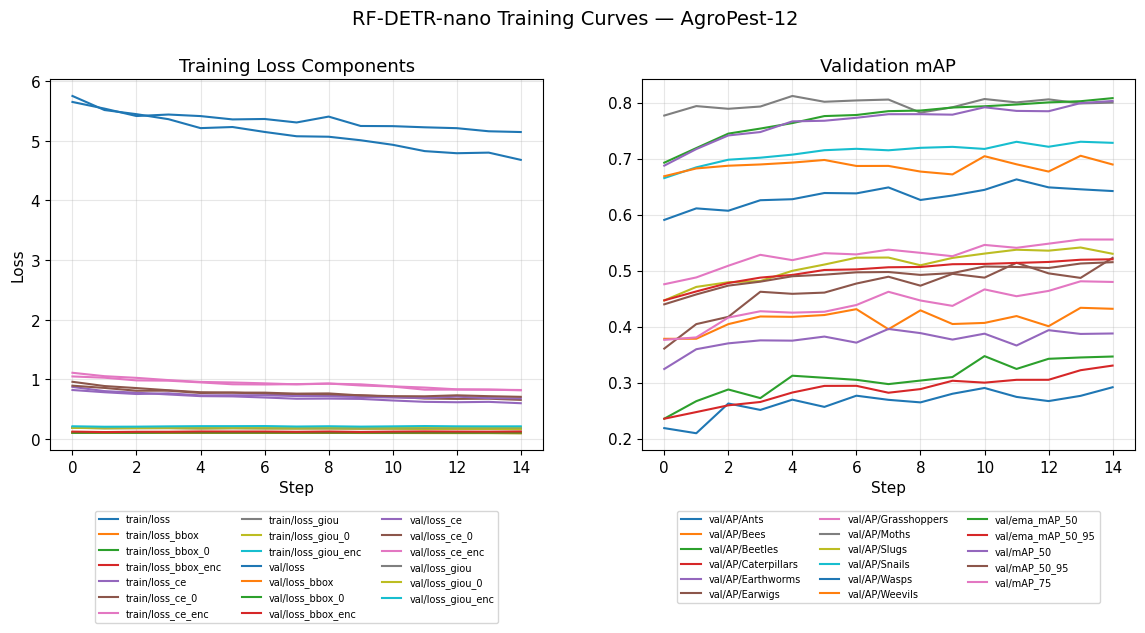

In [6]:
base_path = "/kaggle/input/datasets/sadikshahriar/agropest12-stage2-output/rfdetr_agropest_train_stage2"

log_found = False
csv_logs = []
for d in [base_path]:
    csv_logs += glob.glob(os.path.join(d, "**", "metrics.csv"), recursive=True)
    csv_logs += glob.glob(os.path.join(d, "**", "*.csv"),       recursive=True)
csv_logs = sorted(set(csv_logs))

if csv_logs:
    dfs = []
    for lp in csv_logs:
        try:
            df_t = pd.read_csv(lp)
            if not df_t.empty: dfs.append(df_t)
        except Exception: pass
    if dfs:
        df_log = pd.concat(dfs, ignore_index=True)
        log_found = True
        
        # Increased height slightly to make room for the legends underneath
        fig, axes = plt.subplots(1, 2, figsize=(14, 7))
        
        loss_cols = [c for c in df_log.columns if "loss" in c.lower()]
        if loss_cols:
            for col in loss_cols:
                v = df_log[col].dropna()
                axes[0].plot(range(len(v)), v.values, label=col)
            axes[0].set_title("Training Loss Components")
            axes[0].set_xlabel("Step"); axes[0].set_ylabel("Loss")
            # Place legend outside, centered below the graph in 3 columns
            axes[0].legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
            axes[0].grid(True, alpha=0.3)
            
        map_cols = [c for c in df_log.columns if "map" in c.lower() or "ap" in c.lower()]
        if map_cols:
            for col in map_cols:
                v = df_log[col].dropna()
                axes[1].plot(range(len(v)), v.values, label=col)
            axes[1].set_title("Validation mAP"); axes[1].set_xlabel("Step")
            # Place legend outside, centered below the graph in 3 columns
            axes[1].legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
            axes[1].grid(True, alpha=0.3)
            
        plt.suptitle("RF-DETR-nano Training Curves — AgroPest-12", fontsize=14)
        
        # Add padding at the bottom of the figure so the legends don't get cut off
        fig.subplots_adjust(bottom=0.35)
        plt.show()

if not log_found:
    print("No CSV log found in the Kaggle dataset. (It might have been saved in a different folder during training).")


# Evaluation

Unlike YOLO (`model.val()`), RF-DETR requires manual evaluation:
1. Load best checkpoint (`checkpoint_best_total.pth` per RF-DETR docs)
2. Run `model.predict()` per image
3. Parse YOLO-format GT labels
4. Match predictions to GTs by IoU (greedy, confidence-sorted)
5. Compute mAP@50, mAP@50:95 (COCO all-point interpolation), Precision, Recall, F1

Evaluates on both **validation** and **test** splits.

In [7]:
# ============================================================
# EVALUATION HELPERS
# ============================================================

def parse_yolo_label(label_path, img_w, img_h):
    """Parse YOLO-format label file into xyxy pixel coordinates."""
    boxes, classes = [], []
    if not os.path.exists(label_path):
        return np.zeros((0, 4)), np.zeros(0, dtype=int)
    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5: continue
            cls_id = int(parts[0])
            cx, cy, w, h = [float(x) for x in parts[1:5]]
            boxes.append([(cx-w/2)*img_w, (cy-h/2)*img_h,
                           (cx+w/2)*img_w, (cy+h/2)*img_h])
            classes.append(cls_id)
    if not boxes:
        return np.zeros((0, 4)), np.zeros(0, dtype=int)
    return np.array(boxes), np.array(classes, dtype=int)


def compute_iou_single(box1, box2):
    """Compute IoU between two [x1,y1,x2,y2] boxes."""
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    a1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    a2 = (box2[2]-box2[0]) * (box2[3]-box2[1])
    union = a1 + a2 - inter
    return inter / union if union > 0 else 0.0


def compute_ap_curve(recalls, precisions):
    """COCO-style all-point AP."""
    mrec = np.concatenate(([0.], recalls,    [1.]))
    mpre = np.concatenate(([1.], precisions, [0.]))
    for i in range(len(mpre)-1, 0, -1):
        mpre[i-1] = max(mpre[i-1], mpre[i])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx+1] - mrec[idx]) * mpre[idx+1]))


def compute_metrics_at_iou(all_preds, all_gts, num_classes, iou_threshold):
    """
    Per-class AP, Precision, Recall at a given IoU threshold.
    CRITICAL FIX: scores.append() is INSIDE the per-prediction loop (after both
    if/else branches). Original code only appended in the else-branch, causing
    len(scores) != len(tp_list) and completely wrong mAP values.
    """
    aps = np.zeros(num_classes)
    prec_cls = np.zeros(num_classes)
    rec_cls  = np.zeros(num_classes)

    for cls_id in range(num_classes):
        scores, tp_list = [], []
        total_gt = 0
        for (pred_b, pred_s, pred_c), (gt_b, gt_c) in zip(all_preds, all_gts):
            p_mask = pred_c == cls_id; g_mask = gt_c == cls_id
            cls_pb = pred_b[p_mask]; cls_ps = pred_s[p_mask]; cls_gb = gt_b[g_mask]
            total_gt += len(cls_gb)
            if len(cls_pb) == 0: continue
            gt_matched = np.zeros(len(cls_gb), dtype=bool)
            for pi in np.argsort(-cls_ps):
                best_iou, best_gi = 0, -1
                for gi, gb in enumerate(cls_gb):
                    if gt_matched[gi]: continue
                    iou = compute_iou_single(cls_pb[pi], gb)
                    if iou > best_iou: best_iou, best_gi = iou, gi
                if best_iou >= iou_threshold and best_gi >= 0:
                    tp_list.append(1); gt_matched[best_gi] = True
                else:
                    tp_list.append(0)
                # FIX: must be here — INSIDE loop, OUTSIDE if/else
                scores.append(float(cls_ps[pi]))
        if total_gt == 0 or not scores: continue
        sa = np.array(scores); ta = np.array(tp_list)
        ta = ta[np.argsort(-sa)]
        cum_tp = np.cumsum(ta); cum_fp = np.cumsum(1-ta)
        rec = cum_tp / total_gt; pre = cum_tp / (cum_tp + cum_fp)
        aps[cls_id] = compute_ap_curve(rec, pre)
        total_tp = int(cum_tp[-1])
        prec_cls[cls_id] = total_tp / len(ta) if len(ta) > 0 else 0
        rec_cls[cls_id]  = total_tp / total_gt if total_gt > 0 else 0
    return aps, prec_cls, rec_cls


def evaluate_split(model, split_path, class_names, conf=0.25):
    """Full evaluation on a dataset split."""
    img_dir = os.path.join(split_path, "images")
    lbl_dir = os.path.join(split_path, "labels")
    num_cls = len(class_names)
    iou_thresholds = np.arange(0.5, 1.0, 0.05)
    all_preds, all_gts = [], []
    img_files = sorted([f for f in os.listdir(img_dir)
                        if f.lower().endswith((".jpg",".jpeg",".png"))])
    for img_file in img_files:
        img_path = os.path.join(img_dir, img_file)
        lbl_path = os.path.join(lbl_dir, os.path.splitext(img_file)[0] + ".txt")
        img = cv2.imread(img_path)
        if img is None:
            all_preds.append((np.zeros((0,4)), np.zeros(0), np.zeros(0, dtype=int)))
            all_gts.append((np.zeros((0,4)), np.zeros(0, dtype=int))); continue
        h, w = img.shape[:2]
        dets = model.predict(img_path, threshold=conf)
        if len(dets) > 0:
            pb, ps, pc = dets.xyxy, dets.confidence, dets.class_id
        else:
            pb = np.zeros((0,4)); ps = np.zeros(0); pc = np.zeros(0, dtype=int)
        gt_b, gt_c = parse_yolo_label(lbl_path, w, h)
        all_preds.append((pb, ps, pc)); all_gts.append((gt_b, gt_c))
    aps_per_thresh = [compute_metrics_at_iou(all_preds, all_gts, num_cls, t)[0]
                      for t in iou_thresholds]
    aps_per_thresh = np.array(aps_per_thresh)
    map50_pc = aps_per_thresh[0]; map5095_pc = np.mean(aps_per_thresh, axis=0)
    _, p_pc, r_pc = compute_metrics_at_iou(all_preds, all_gts, num_cls, 0.5)
    f1_pc = 2*p_pc*r_pc / (p_pc+r_pc+1e-16)
    return {"map50": float(np.mean(map50_pc)), "map5095": float(np.mean(map5095_pc)),
            "precision": float(np.mean(p_pc)), "recall": float(np.mean(r_pc)),
            "f1": float(np.mean(f1_pc)),
            "map50_pc": map50_pc, "map5095_pc": map5095_pc,
            "p_pc": p_pc, "r_pc": r_pc, "f1_pc": f1_pc,
            "all_preds": all_preds, "all_gts": all_gts, "img_files": img_files}


def build_confusion_matrix(all_preds, all_gts, num_cls, iou_threshold=0.5):
    """
    (num_cls+1) x (num_cls+1) confusion matrix.
    FIX: moved to module level (was inside evaluation try-block with broken indentation).
    """
    cm = np.zeros((num_cls+1, num_cls+1), dtype=int)
    for (pb, ps, pc), (gb, gc) in zip(all_preds, all_gts):
        gt_matched = np.zeros(len(gb), dtype=bool)
        for pi in (np.argsort(-ps) if len(ps) > 0 else []):
            best_iou, best_gi = 0, -1
            for gi in range(len(gb)):
                if gt_matched[gi]: continue
                iou = compute_iou_single(pb[pi], gb[gi])
                if iou > best_iou: best_iou, best_gi = iou, gi
            if best_iou >= iou_threshold and best_gi >= 0:
                cm[int(gc[best_gi]), int(pc[pi])] += 1
                gt_matched[best_gi] = True
            else:
                cm[num_cls, int(pc[pi])] += 1
        for gi in range(len(gb)):
            if not gt_matched[gi]: cm[int(gc[gi]), num_cls] += 1
    return cm


print("Helpers defined: parse_yolo_label, compute_iou_single, compute_ap_curve")
print("  compute_metrics_at_iou [FIXED: scores.append inside loop]")
print("  evaluate_split, build_confusion_matrix [FIXED: module-level]")

Helpers defined: parse_yolo_label, compute_iou_single, compute_ap_curve
  compute_metrics_at_iou [FIXED: scores.append inside loop]
  evaluate_split, build_confusion_matrix [FIXED: module-level]


In [8]:
import os, glob

# =========================================================================
# ⚠️ KAGGLE DATASET CONFIGURATION ⚠️
# =========================================================================

# The exact path to the output folder containing your checkpoints
base_path = "/kaggle/input/datasets/sadikshahriar/agropest12-stage2-output/rfdetr_agropest_train_stage2"

# Automatically find the best checkpoint in your uploaded dataset
best_ckpt = None
for fname in ["checkpoint_best_total.pth", "checkpoint_best_ema.pth", "checkpoint_best_regular.pth"]:
    cand = os.path.join(base_path, fname)
    if os.path.exists(cand):
        best_ckpt = cand; break

if best_ckpt is None:
    cands = sorted(glob.glob(os.path.join(base_path, "checkpoint*.pth")))
    best_ckpt = cands[-1] if cands else None

assert best_ckpt is not None, f"Could not find checkpoint in {base_path}! Make sure your dataset name is correct."

print(f"Loading best checkpoint for evaluation: {best_ckpt}")

model_eval = RFDETRNano(pretrain_weights=best_ckpt, resolution=RESOLUTION)

print("\n" + "="*55)
print("  FINAL EVALUATION ON TEST SET")
print("="*55)

# Define the confidence threshold for evaluation
CONF_THRESH = 0.25

# Run the custom evaluation loop on the test set
# (Make sure you have run the EVALUATION HELPERS cell below this one first!)
test_dir = os.path.join(CLEANED_PATH, "test")
print("Running manual inference loop for evaluation...")
results = evaluate_split(model_eval, test_dir, CLASS_NAMES, conf=CONF_THRESH)

print(f"\nFinal Test mAP@50:95 : {results['map5095']:.4f}")
print(f"Final Test mAP@50    : {results['map50']:.4f}")
print(f"Final Test F1-Score  : {results['f1']:.4f}")


[2026-07-11 20:12:43] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-07-11 20:12:43] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


Loading best checkpoint for evaluation: /kaggle/input/datasets/sadikshahriar/agropest12-stage2-output/rfdetr_agropest_train_stage2/checkpoint_best_total.pth


[2026-07-11 20:12:44] [WARNING] rf-detr - Checkpoint has 12 classes but model is configured for 90. Using checkpoint class count (12). Pass num_classes=12 to suppress this warning.
[2026-07-11 20:12:44] [WARNING] rf-detr - load_pretrain_weights: args.num_queries absent; inferred ckpt_num_queries=300 from tensor rows 3900 ÷ ckpt_group_detr=13.



  FINAL EVALUATION ON TEST SET
Running manual inference loop for evaluation...


[2026-07-11 20:12:45] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.optimize_for_inference(dtype=torch.float16).



Final Test mAP@50:95 : 0.3615
Final Test mAP@50    : 0.5705
Final Test F1-Score  : 0.5315



Evaluating on VALIDATION set...

Validation: P=0.4723 R=0.6866 mAP50=0.5625 mAP50:95=0.3588 F1=0.5545
----------------------------------------

Evaluating on TEST set...

Test: P=0.4368 R=0.6928 mAP50=0.5705 mAP50:95=0.3615 F1=0.5315
----------------------------------------

Per-Class Metrics (Test Set):


,Class,Precision,Recall,mAP@50,mAP@50-95,F1
0,Ants,0.3333,0.6552,0.4719,0.1842,0.4419
1,Bees,0.4571,0.7273,0.6584,0.3696,0.5614
2,Beetles,0.2892,0.5581,0.3354,0.1968,0.3810
3,Caterpillars,0.3212,0.4731,0.3442,0.1737,0.3826
4,Earthworms,0.2110,0.5750,0.2915,0.1554,0.3087
5,Earwigs,0.3271,0.4795,0.3459,0.1977,0.3889
6,Grasshoppers,0.2800,0.5091,0.3842,0.2305,0.3613
7,Moths,0.7258,1.0000,0.9910,0.8304,0.8411
8,Slugs,0.4595,0.6667,0.5844,0.3784,0.5440
9,Snails,0.6377,0.8800,0.8282,0.5642,0.7395


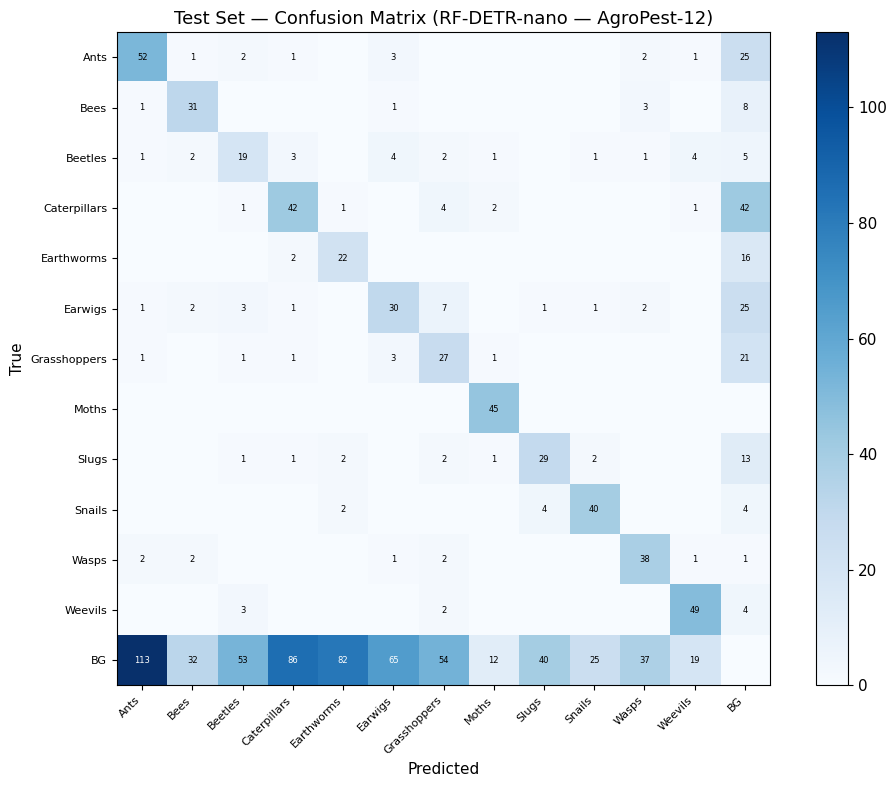


Inference (100 images, single-image sequential):
  Total: 4.90 s | FPS: 20.4 | Per-image: 49.0 ms


In [9]:
# ============================================================
# COMPREHENSIVE EVALUATION (Metrics, Confusion Matrix, FPS)
# ============================================================
eval_success = False; test_results = None; val_results = None

try:
    # --- 1. Validation ---
    print("\nEvaluating on VALIDATION set...")
    val_results = evaluate_split(model_eval, os.path.join(CLEANED_PATH, "valid"), CLASS_NAMES, CONF_THRESH)
    print(f"\nValidation: P={val_results['precision']:.4f} R={val_results['recall']:.4f}"
          f" mAP50={val_results['map50']:.4f} mAP50:95={val_results['map5095']:.4f}"
          f" F1={val_results['f1']:.4f}")
    print("-" * 40)

    # --- 2. Test ---
    print("\nEvaluating on TEST set...")
    test_results = evaluate_split(model_eval, os.path.join(CLEANED_PATH, "test"), CLASS_NAMES, CONF_THRESH)
    print(f"\nTest: P={test_results['precision']:.4f} R={test_results['recall']:.4f}"
          f" mAP50={test_results['map50']:.4f} mAP50:95={test_results['map5095']:.4f}"
          f" F1={test_results['f1']:.4f}")
    print("-" * 40)

    # --- 3. Per-Class Table ---
    df_pc = pd.DataFrame({
        "Class"    : CLASS_NAMES,
        "Precision": np.round(test_results["p_pc"],       4),
        "Recall"   : np.round(test_results["r_pc"],       4),
        "mAP@50"   : np.round(test_results["map50_pc"],   4),
        "mAP@50-95": np.round(test_results["map5095_pc"], 4),
        "F1"       : np.round(test_results["f1_pc"],      4),
    })
    print("\nPer-Class Metrics (Test Set):"); display(df_pc)

    # --- 4. Confusion Matrix ---
    cm = build_confusion_matrix(test_results["all_preds"], test_results["all_gts"], NUM_CLASSES)
    labels = CLASS_NAMES + ["BG"]
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title("Test Set — Confusion Matrix (RF-DETR-nano — AgroPest-12)")
    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j] > 0:
                ax.text(j, i, str(cm[i,j]), ha="center", va="center", fontsize=6,
                        color="white" if cm[i,j] > cm.max()/2 else "black")
    plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

    # --- 5. Inference FPS ---
    _fps_dir = os.path.join(CLEANED_PATH, "test", "images")
    fps_imgs = sorted([os.path.join(_fps_dir, f) for f in os.listdir(_fps_dir)
                       if f.lower().endswith((".jpg",".jpeg",".png"))])[:100]
    _ = model_eval.predict(fps_imgs[0], threshold=CONF_THRESH)  # warmup
    t0 = time.time()
    for img_p in fps_imgs: _ = model_eval.predict(img_p, threshold=CONF_THRESH)
    t_total = time.time() - t0
    fps = len(fps_imgs) / t_total
    print(f"\nInference ({len(fps_imgs)} images, single-image sequential):")
    print(f"  Total: {t_total:.2f} s | FPS: {fps:.1f} | Per-image: {t_total/len(fps_imgs)*1000:.1f} ms")

    eval_success = True

except Exception as e:
    print(f"\n!!! Evaluation failed: {e}")
    import traceback; traceback.print_exc()
    print("Skipping remaining evaluation cells.")


# Model Inference — Sample Predictions by Class

Select **3 images per class** (up to 36 total) from the test set, run inference,
and visualise predictions with colour-coded bounding boxes.

Images per class: {'Weevils': 3, 'Ants': 3, 'Bees': 3, 'Beetles': 3, 'Caterpillars': 3, 'Earthworms': 3, 'Earwigs': 3, 'Grasshoppers': 3, 'Moths': 3, 'Slugs': 3, 'Snails': 3, 'Wasps': 3}
Running inference on 36 images...


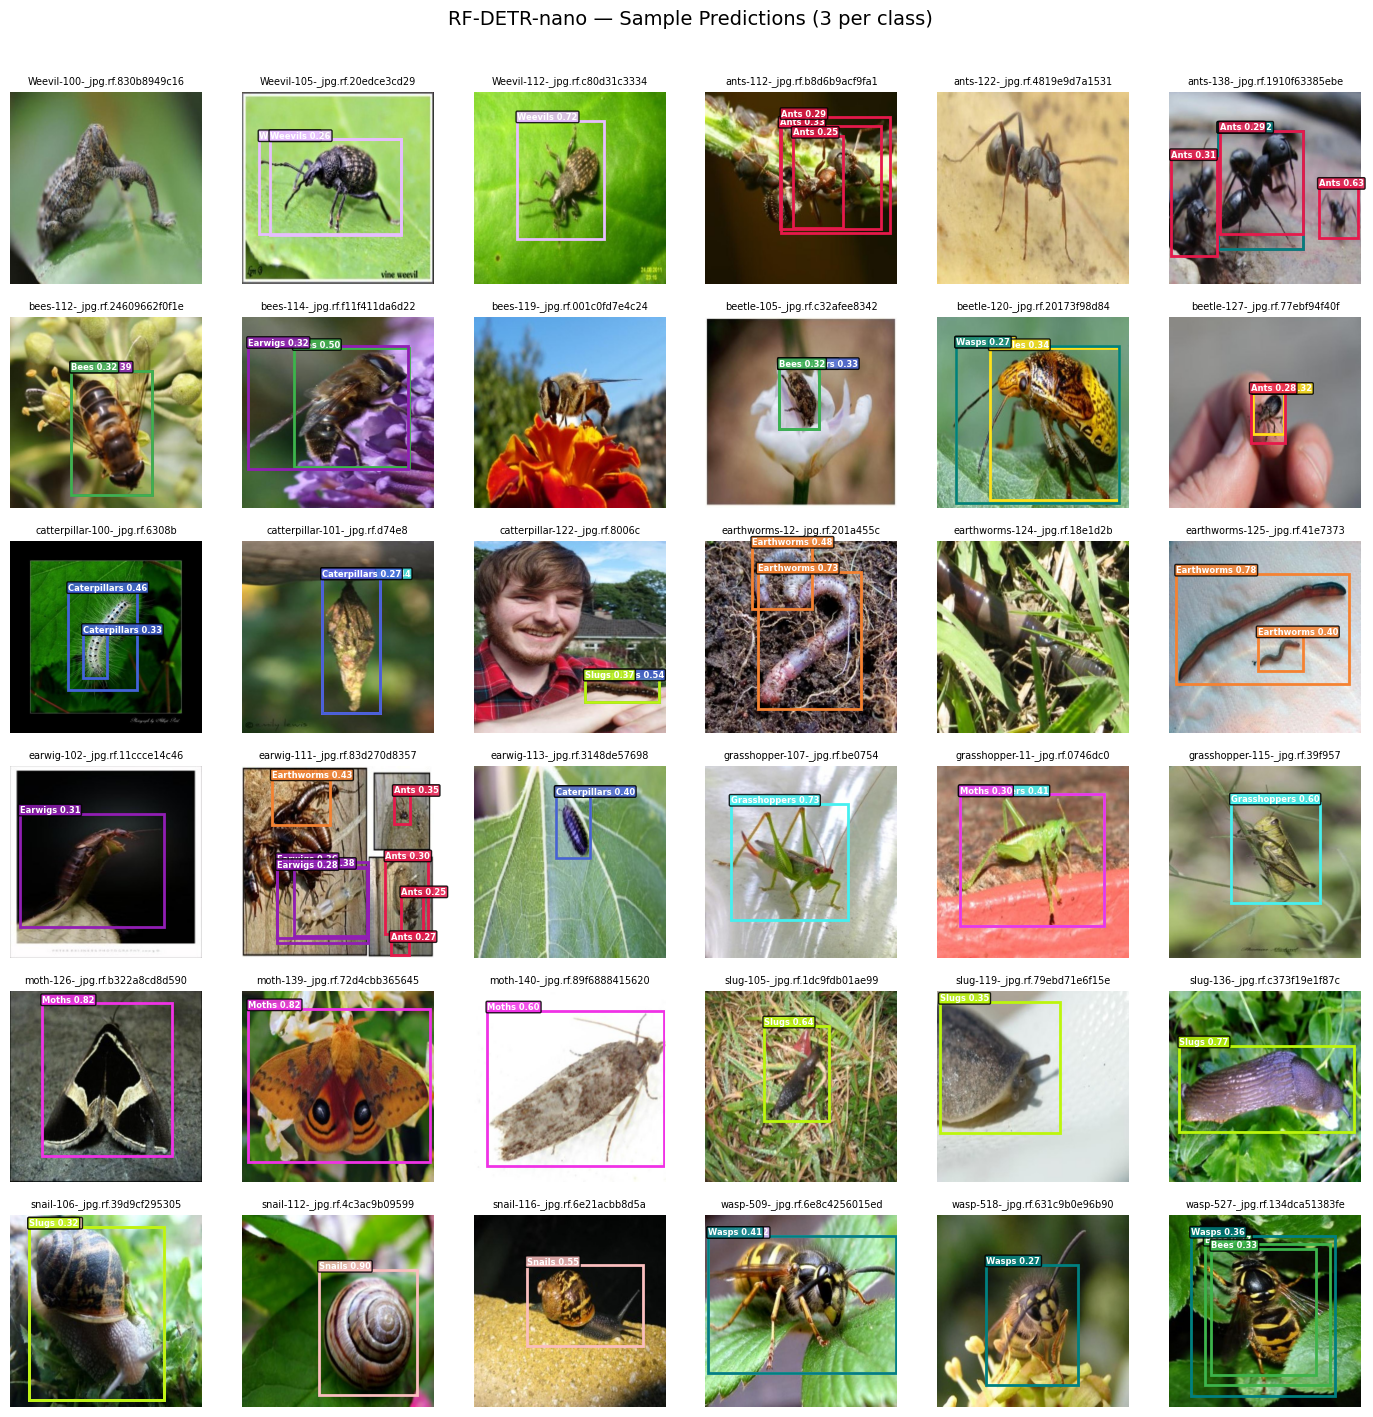


Correctness log:
             Ants: 2/3 (67%)
             Bees: 2/3 (67%)
          Beetles: 3/3 (100%)
     Caterpillars: 3/3 (100%)
       Earthworms: 2/3 (67%)
          Earwigs: 1/3 (33%)
     Grasshoppers: 3/3 (100%)
            Moths: 3/3 (100%)
            Slugs: 3/3 (100%)
           Snails: 2/3 (67%)
            Wasps: 3/3 (100%)
          Weevils: 2/3 (67%)
          OVERALL: 29/36 (81%)


In [10]:
_img_dir = os.path.join(CLEANED_PATH, "test", "images")
_lbl_dir = os.path.join(CLEANED_PATH, "test", "labels")

# FIX: if/else guard instead of bare 'return' (SyntaxError in notebook cells)
_model_ok = "model_eval" in dir() and model_eval is not None
if not _model_ok:
    print("SKIPPING: No model loaded.")
else:
    class_images = defaultdict(list)
    for img_file in sorted(os.listdir(_img_dir)):
        if not img_file.lower().endswith((".jpg",".jpeg",".png")): continue
        lp = os.path.join(_lbl_dir, os.path.splitext(img_file)[0] + ".txt")
        if not os.path.exists(lp): continue
        with open(lp) as f:
            for line in f:
                cid = int(line.strip().split()[0])
                if len(class_images[cid]) < 3: class_images[cid].append(img_file)
                break
    print("Images per class:", {CLASS_NAMES[k]: len(v) for k,v in class_images.items()})
    selected = sorted(set(img for imgs in class_images.values() for img in imgs))
    print(f"Running inference on {len(selected)} images...")

    n_cols = 6; n_rows = max(1, (len(selected)+n_cols-1)//n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 14))
    axes = axes.flatten()
    for idx, img_file in enumerate(selected):
        img_path = os.path.join(_img_dir, img_file)
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        dets = model_eval.predict(img_path, threshold=CONF_THRESH)
        axes[idx].imshow(img_rgb)
        if len(dets) > 0:
            for i in range(len(dets)):
                x1,y1,x2,y2 = dets.xyxy[i]; cid = int(dets.class_id[i])
                conf_ = float(dets.confidence[i]); color = CLASS_COLORS[cid%len(CLASS_COLORS)]
                axes[idx].add_patch(mpatches.Rectangle((x1,y1),x2-x1,y2-y1,
                    fill=False, edgecolor=color, linewidth=2))
                axes[idx].text(x1, max(y1-4,10), f"{CLASS_NAMES[cid]} {conf_:.2f}",
                    fontsize=6, color="white", weight="bold",
                    bbox=dict(boxstyle="round,pad=0.15",facecolor=color,alpha=0.85))
        axes[idx].set_title(img_file[:30], fontsize=7); axes[idx].axis("off")
    for idx in range(len(selected), len(axes)): axes[idx].axis("off")
    plt.suptitle("RF-DETR-nano — Sample Predictions (3 per class)", fontsize=14, y=1.01)
    plt.tight_layout(); plt.show()

    # Quick per-class accuracy log
    print("\nCorrectness log:")
    correct_total, total_total = 0, 0
    for cid in range(NUM_CLASSES):
        correct = 0
        for img_file in class_images.get(cid, []):
            total_total += 1
            img_path = os.path.join(_img_dir, img_file)
            lp = os.path.join(_lbl_dir, os.path.splitext(img_file)[0] + ".txt")
            img = cv2.imread(img_path)
            if img is None: continue
            h, w = img.shape[:2]
            gt_boxes = []
            if os.path.exists(lp):
                with open(lp) as f:
                    for line in f:
                        p = line.strip().split()
                        if len(p) >= 5:
                            gcls=int(float(p[0])); cx,cy,bw,bh=map(float,p[1:5])
                            gt_boxes.append((gcls,int((cx-bw/2)*w),int((cy-bh/2)*h),
                                             int((cx+bw/2)*w),int((cy+bh/2)*h)))
            dets = model_eval.predict(img_path, threshold=CONF_THRESH)
            pred_boxes = []
            if len(dets) > 0:
                for i in range(len(dets)):
                    pcls=int(dets.class_id[i]); px1,py1,px2,py2=dets.xyxy[i]
                    pred_boxes.append((pcls,int(px1),int(py1),int(px2),int(py2)))
            found = False
            for gcls,gx1,gy1,gx2,gy2 in gt_boxes:
                if gcls != cid: continue
                for pcls,px1,py1,px2,py2 in pred_boxes:
                    if pcls==cid and compute_iou_single([gx1,gy1,gx2,gy2],[px1,py1,px2,py2])>=0.5:
                        found=True; break
                if found: break
            if found: correct += 1; correct_total += 1
        total = len(class_images.get(cid, []))
        acc = correct/total*100 if total > 0 else 0
        print(f"  {CLASS_NAMES[cid]:>15}: {correct}/{total} ({acc:.0f}%)")
    if total_total > 0:
        print(f"  {'OVERALL':>15}: {correct_total}/{total_total} ({correct_total/total_total*100:.0f}%)")


# Error Analysis

- **≥ 3 False Negatives:** GT objects missed by the detector (ranked by area).
- **≥ 3 False Positives:** Detections with no GT match (ranked by confidence).
- **Localization errors:** Correct class, IoU 0.3–0.5.
- **Failure-pattern summary** comparing RF-DETR vs YOLO failure modes.

---

**Failure-Pattern Summary**

**Dominant failure mode for RF-DETR on AgroPest-12:**
RF-DETR’s primary failures involve **confusion between visually similar species**
(Slugs vs Snails, Bees vs Wasps, Caterpillars vs Earthworms).

**Comparison with YOLO:**
- **Duplicate detections:** RF-DETR’s bipartite matching eliminates this YOLO failure mode.
- **Small objects:** DINOv2 global context may improve detection vs YOLO’s CNN backbone.
- **Speed:** RF-DETR is slower than YOLO at equal accuracy; YOLO better for real-time.
- **Convergence:** RF-DETR converges in fewer epochs (20 vs 50) due to DINOv2 pre-training.

FN: 164 | FP-bg: 581 | Miscls: 98 | LocErr: 37

--- TOP 3 FALSE NEGATIVES ---
  FN 1: earwig-165-_jpg.rf.98ff25cee96863a57cf23bafba — Earwigs (area=329569px²)


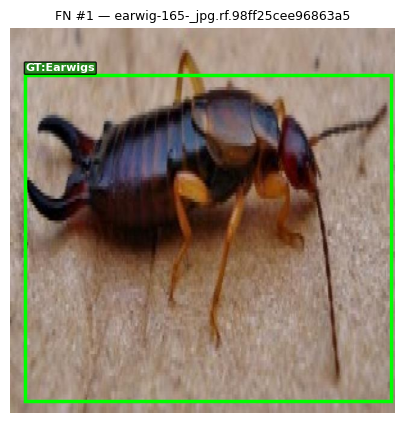

  FN 2: earwig-341-_jpg.rf.07cc2ebd85070a72ceb74bd1e4 — Earwigs (area=319920px²)


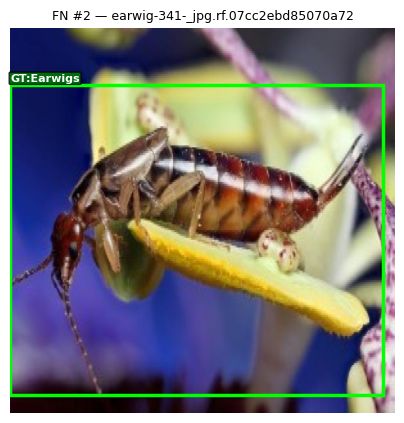

  FN 3: slug-94-_jpg.rf.45283f7f2eae12a6c47628ea6863f — Slugs (area=286572px²)


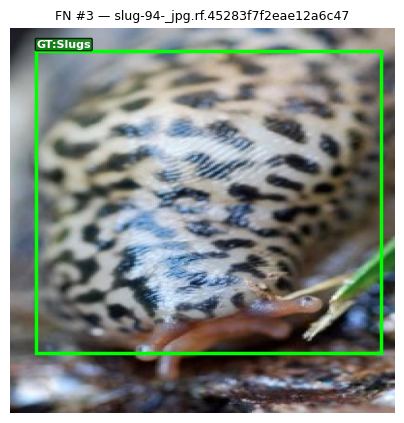


--- TOP 3 FALSE POSITIVES ---
  FP 1: beetle-350-_jpg.rf.f7575adcb244eceb3a667561d6 — Pred:Weevils GT:Beetles (MISCLS, conf=0.830)


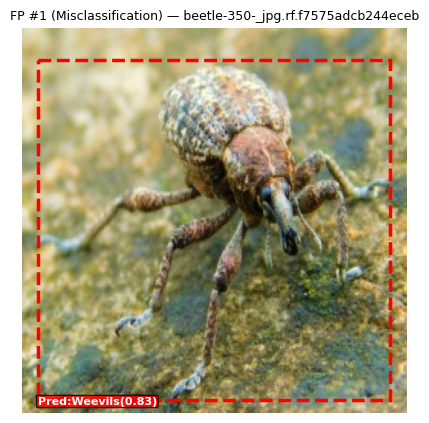

  FP 2: beetle-189-_jpg.rf.34568723dda6fdf488e2446b5f — Pred:Moths GT:Beetles (MISCLS, conf=0.751)


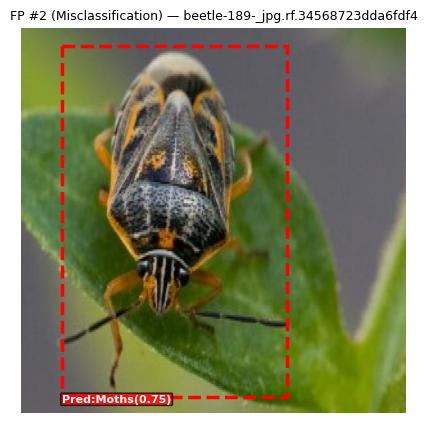

  FP 3: beetle-388-_jpg.rf.2d0c284e96024d9a05f4691c7d — Pred:Caterpillars GT:Beetles (MISCLS, conf=0.729)


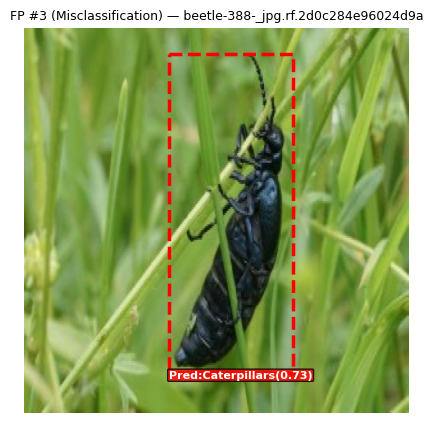


--- TOP 3 LOCALIZATION ERRORS (IoU 0.3-0.5) ---
  LocErr 1: catterpillar-128-_jpg.rf.b4d158742d3db26 — Caterpillars IoU=0.342 conf=0.723


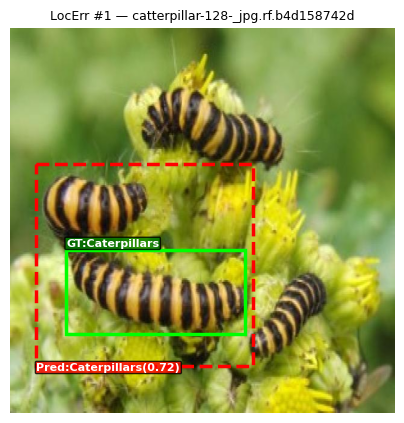

  LocErr 2: earthworms-135-_jpg.rf.043a9953d8e3f4e7b — Earthworms IoU=0.399 conf=0.649


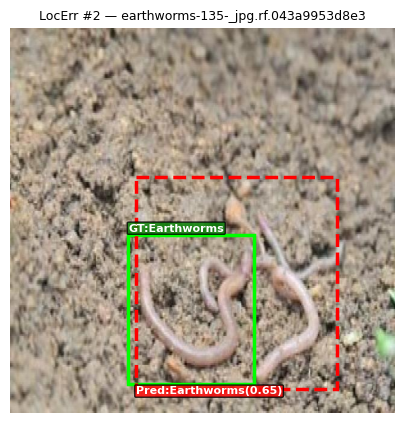

  LocErr 3: catterpillar-168-_jpg.rf.67f8e880f5a6ea6 — Caterpillars IoU=0.373 conf=0.614


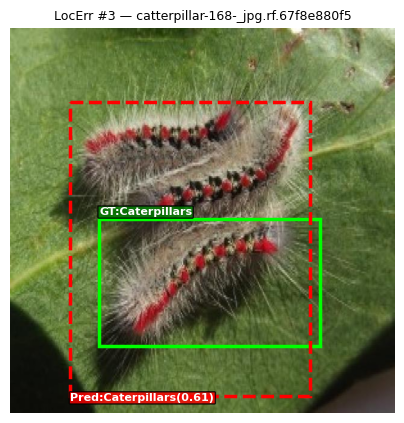

In [11]:
# FIX: if/else guard instead of bare 'return' (SyntaxError at module level)
_ea_ok = "results" in dir() and results is not None and len(results.get("img_files", [])) > 0

if not _ea_ok:
    print("SKIPPING: No evaluation results (evaluation cell may have failed).")
else:
    try:
        _ea_img = os.path.join(CLEANED_PATH, "test", "images")
        fn_examples, fp_bg, fp_miscls, locerr = [], [], [], []

        for img_idx, img_file in enumerate(results["img_files"]):
            img_path = os.path.join(_ea_img, img_file)
            pred_b, pred_s, pred_c = results["all_preds"][img_idx]
            gt_b, gt_c = results["all_gts"][img_idx]
            gt_matched   = np.zeros(len(gt_b),   dtype=bool)
            pred_matched = np.zeros(len(pred_b), dtype=bool)

            for pi in (np.argsort(-pred_s) if len(pred_s) > 0 else []):
                best_iou, best_gi = 0, -1
                for gi in range(len(gt_b)):
                    if gt_matched[gi]: continue
                    iou = compute_iou_single(pred_b[pi], gt_b[gi])
                    if iou > best_iou: best_iou, best_gi = iou, gi

                # FIX: proper if/elif/else — original had 'elif' AFTER 'else' (SyntaxError)
                if best_iou >= 0.5 and best_gi >= 0:
                    gt_matched[best_gi] = True; pred_matched[pi] = True
                    if int(pred_c[pi]) != int(gt_c[best_gi]):
                        fp_miscls.append((img_path, pred_b[pi].tolist(),
                            CLASS_NAMES[int(pred_c[pi])], CLASS_NAMES[int(gt_c[best_gi])],
                            float(pred_s[pi]), img_file))
                elif best_iou >= 0.3 and best_gi >= 0 and int(pred_c[pi]) == int(gt_c[best_gi]):
                    locerr.append((img_path, pred_b[pi].tolist(),
                        CLASS_NAMES[int(pred_c[pi])], gt_b[best_gi].tolist(),
                        best_iou, float(pred_s[pi]), img_file))
                else:
                    fp_bg.append((img_path, pred_b[pi].tolist(),
                        CLASS_NAMES[int(pred_c[pi])], float(pred_s[pi]), img_file))

            for gi in range(len(gt_b)):
                if not gt_matched[gi]:
                    box = gt_b[gi]; area = (box[2]-box[0])*(box[3]-box[1])
                    fn_examples.append((img_path, box.tolist(),
                        CLASS_NAMES[int(gt_c[gi])], area, img_file))

        fn_examples.sort(key=lambda x: -x[3])
        fp_bg.sort(key=lambda x: -x[3])
        fp_miscls.sort(key=lambda x: -x[4])
        locerr.sort(key=lambda x: -x[5])
        fp_all = sorted(list(fp_miscls) + list(fp_bg), key=lambda x: -x[-2])

        print(f"FN: {len(fn_examples)} | FP-bg: {len(fp_bg)} | Miscls: {len(fp_miscls)} | LocErr: {len(locerr)}")

        def draw_err(img_path, gt_box=None, gt_label=None,
                     pred_box=None, pred_label=None, pred_conf=None, title=""):
            img = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            fig, ax = plt.subplots(figsize=(5, 5)); ax.imshow(img_rgb)
            if gt_box:
                x1,y1,x2,y2 = gt_box
                ax.add_patch(mpatches.Rectangle((x1,y1),x2-x1,y2-y1,
                    fill=False,edgecolor="lime",linewidth=2.5))
                if gt_label: ax.text(x1,max(y1-6,6),f"GT:{gt_label}",fontsize=8,
                    color="white",weight="bold",bbox=dict(boxstyle="round,pad=0.1",
                    facecolor="green",alpha=0.8))
            if pred_box:
                x1,y1,x2,y2 = pred_box
                ax.add_patch(mpatches.Rectangle((x1,y1),x2-x1,y2-y1,
                    fill=False,edgecolor="red",linewidth=2.5,linestyle="--"))
                if pred_label:
                    lbl = f"Pred:{pred_label}" + (f"({pred_conf:.2f})" if pred_conf else "")
                    ax.text(x1,max(y2+8,6),lbl,fontsize=8,color="white",weight="bold",
                        bbox=dict(boxstyle="round,pad=0.1",facecolor="red",alpha=0.8))
            ax.set_title(f"{title} — {os.path.basename(img_path)[:35]}",fontsize=9)
            ax.axis("off"); return fig

        TOP_N = 3

        print(f"\n--- TOP {TOP_N} FALSE NEGATIVES ---")
        for i in range(min(TOP_N, len(fn_examples))):
            img_path, gt_box, gt_cls, area, fname = fn_examples[i]
            print(f"  FN {i+1}: {fname[:45]} — {gt_cls} (area={area:.0f}px²)")
            fig = draw_err(img_path, gt_box=gt_box, gt_label=gt_cls, title=f"FN #{i+1}")
            plt.show(); plt.close(fig)

        print(f"\n--- TOP {TOP_N} FALSE POSITIVES ---")
        for i in range(min(TOP_N, len(fp_all))):
            item = fp_all[i]
            if len(item) == 6:  # misclassification
                img_path, pred_box, pred_cls, gt_cls, pred_conf, fname = item
                print(f"  FP {i+1}: {fname[:45]} — Pred:{pred_cls} GT:{gt_cls} (MISCLS, conf={pred_conf:.3f})")
                fig = draw_err(img_path, pred_box=pred_box, pred_label=pred_cls,
                    pred_conf=pred_conf, title=f"FP #{i+1} (Misclassification)")
            else:  # background FP
                img_path, pred_box, pred_cls, pred_conf, fname = item
                print(f"  FP {i+1}: {fname[:45]} — Pred:{pred_cls} BACKGROUND (conf={pred_conf:.3f})")
                fig = draw_err(img_path, pred_box=pred_box, pred_label=pred_cls,
                    pred_conf=pred_conf, title=f"FP #{i+1} (Background)")
            plt.show(); plt.close(fig)

        if locerr:
            print(f"\n--- TOP {min(TOP_N,len(locerr))} LOCALIZATION ERRORS (IoU 0.3-0.5) ---")
            for i in range(min(TOP_N, len(locerr))):
                img_path,pred_box,pred_cls,gt_box,iou_v,pred_conf,fname = locerr[i]
                print(f"  LocErr {i+1}: {fname[:40]} — {pred_cls} IoU={iou_v:.3f} conf={pred_conf:.3f}")
                fig = draw_err(img_path,gt_box=gt_box,gt_label=pred_cls,
                    pred_box=pred_box,pred_label=pred_cls,pred_conf=pred_conf,
                    title=f"LocErr #{i+1}")
                plt.show(); plt.close(fig)

    except Exception as e:
        print(f"!!! Error analysis failed: {e}")
        import traceback; traceback.print_exc()
